In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas

In [2]:
"""
Tweak recombination map format by:
- Renaming "Arm" column to "Chrom"
- Relabeling chromosome arms with file "data/chr_map.txt"
- Renaming rate column from "c (cM/Mb)" to "cM/Mb"
"""
col_names = ["Chrom", "Start", "Stop", "cM/Mb"]
df = pandas.read_csv("data/recomb_r6_num.tsv", sep="\\s+", names=col_names, skiprows=1)
chr_map_df = pandas.read_csv("data/chr_map.txt", sep="\\s+", names=["arm", "code"])
chr_map = {int(chr_map_df.loc[i, "code"]): chr_map_df.loc[i, "arm"]
           for i in range(len(chr_map_df))}
df.Chrom = [chr_map[x] for x in df["Chrom"]]
print(df)
df.to_csv("data/recomb_build6.tsv", sep="\t", index=0)

FileNotFoundError: [Errno 2] No such file or directory: 'data/recomb_r6_num.tsv'

Text(0, 0.5, 'map (M)')

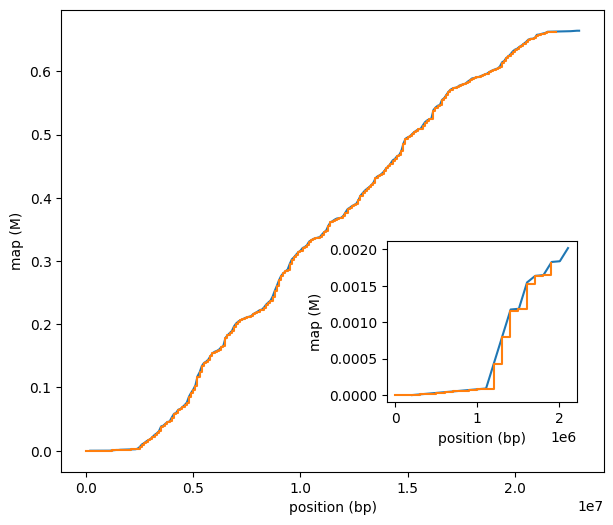

In [3]:
"""
Computing map distances from a recombination map.
AncestryHMM needs map distances in M between marker i-1 and marker i
in row i. The value in row 0 doesn't matter.
"""
# Pick some arbitrary 1-indexed sites. 
sites = np.arange(0, 22000000, 100000) + 1

df = pandas.read_csv("data/recomb_build6.tsv", sep="\\s+")
# Subset to one chromosome and extract arrays
df_X = df[df["Chrom"] == "X"]
starts = np.array(df_X["Start"])
stops = np.array(df_X["Stop"])
# Convert from cM/Mb to cM/bp
rates_M = np.array(df_X["cM/Mb"]) * 1e-8
# Calculate sites spanned by each interval
map_spans_bp = stops - starts + 1
map_spans_M = map_spans_bp * rates_M
map_M = np.cumsum(map_spans_M)
map_M = np.concatenate([[0], map_M])
map_bp = np.concatenate([[starts[0]], stops])
# Interpolate site map coordinates
site_M = np.interp(sites, map_bp, map_M)
site_M_diffs = np.concatenate([[0], site_M[1:] - site_M[:-1]])

fig, ax = plt.subplots(1, 1, figsize=(7, 6))
ax.plot(map_bp, map_M)
ax.set_xlabel("position (bp)")
ax.set_ylabel("map (M)")
ax.step(sites, np.cumsum(site_M_diffs), where="post")
inset = ax.inset_axes((0.6, 0.15, 0.35, 0.35))
inset.plot(map_bp[:20], map_M[:20])
inset.step(sites[:20], np.cumsum(site_M_diffs)[:20], where="post")
inset.set_xlabel("position (bp)")
inset.set_ylabel("map (M)")